# Adjustability Results

In [11]:
# Setup: paths, imports and the white-background fivethirtyeight theme shared by every cell below.
# Part I (adjustability) works on data/adjustability.parquet; Part II (adjustability value) works on
# data/adjustability_value.parquet and keeps its frame in `cf` so the two halves cannot clobber
# each other. Leaderboards are rendered by src/uncommited/leaderboard_table.R.
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data').exists())
DATA = ROOT / 'data'
PLOTS = ROOT / 'results' / 'plots'
PLOTS.mkdir(parents=True, exist_ok=True)

# fivethirtyeight on a white background (grid color set explicitly; FT's default grid is white).
FT = ['fivethirtyeight', {'figure.facecolor': 'white', 'axes.facecolor': 'white',
                          'savefig.facecolor': 'white', 'grid.color': '#cbcbcb'}]


def plot_path(name):
    """Route a figure filename to its results/plots/<category> subfolder (mirrored in the R
    generator and the other results notebooks)."""
    sub = ('adjustability' if name.startswith('adjustability')
           else 'repertoire' if name.startswith('repertoire')
           else 'predictiveness')
    d = PLOTS / sub
    d.mkdir(parents=True, exist_ok=True)
    return d / name


In [12]:
# Data section: sample sizes for the paper.
# Part I uses adjustability.parquet (trait measure, 471 units).
# Part II uses adjustability_value.parquet (466 units after the pitch-characteristic join).
_KEY = ['batter_id', 'batter_stand']

_adj = pd.read_parquet(DATA / 'adjustability.parquet')
_n_units_trait = _adj.groupby(_KEY).ngroups

_val = pd.read_parquet(DATA / 'adjustability_value.parquet')
_n_units_val  = len(_val)
_n_swings_val = int(_val['n_swings'].sum())

print("=== Data section ===")
print(f"Trait (adjustability.parquet):       {_n_units_trait:>5} units           [expect 471]")
print(f"Value (adjustability_value.parquet): {_n_units_val:>5} units  "
      f"{_n_swings_val:>9,} swings  [expect 466 / 553,459]")
print()
print("Unit: (batter, batting stance) — switch hitters appear twice.")
print("Seasons: 2024–25. 2026 is a partial-season holdout used only for xRV model testing.")
print("Competitive-swing filter: bat-tracked · not a bunt · bat_speed ≥ 50 mph")
print("  · |horz_attack_angle| ≤ 45° · vert_attack_angle ∈ [−45°, 75°].")
print("Minimum swings: ≥ 400 per unit for the value analysis; ≥ 150 for clustering.")

=== Data section ===
Trait (adjustability.parquet):         471 units           [expect 471]
Value (adjustability_value.parquet):   466 units    553,459 swings  [expect 466 / 553,459]

Unit: (batter, batting stance) — switch hitters appear twice.
Seasons: 2024–25. 2026 is a partial-season holdout used only for xRV model testing.
Competitive-swing filter: bat-tracked · not a bunt · bat_speed ≥ 50 mph
  · |horz_attack_angle| ≤ 45° · vert_attack_angle ∈ [−45°, 75°].
Minimum swings: ≥ 400 per unit for the value analysis; ≥ 150 for clustering.


## Adjustability leaderboard 

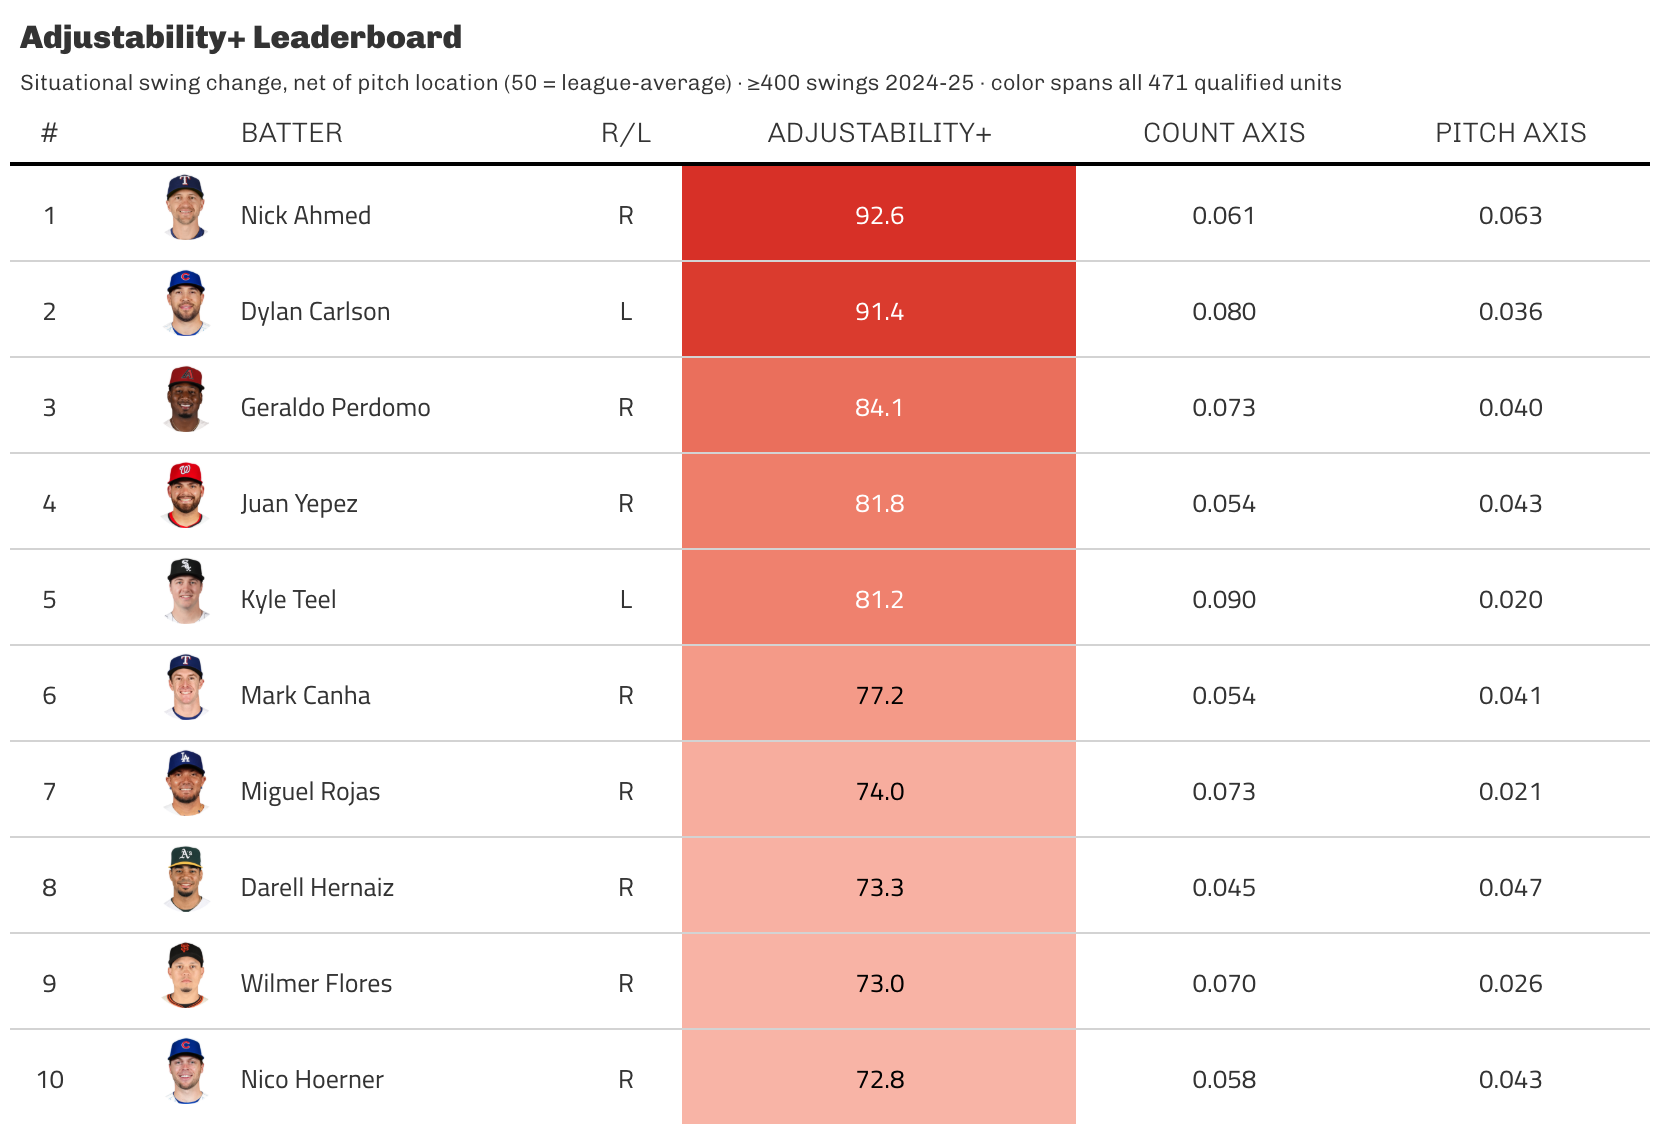

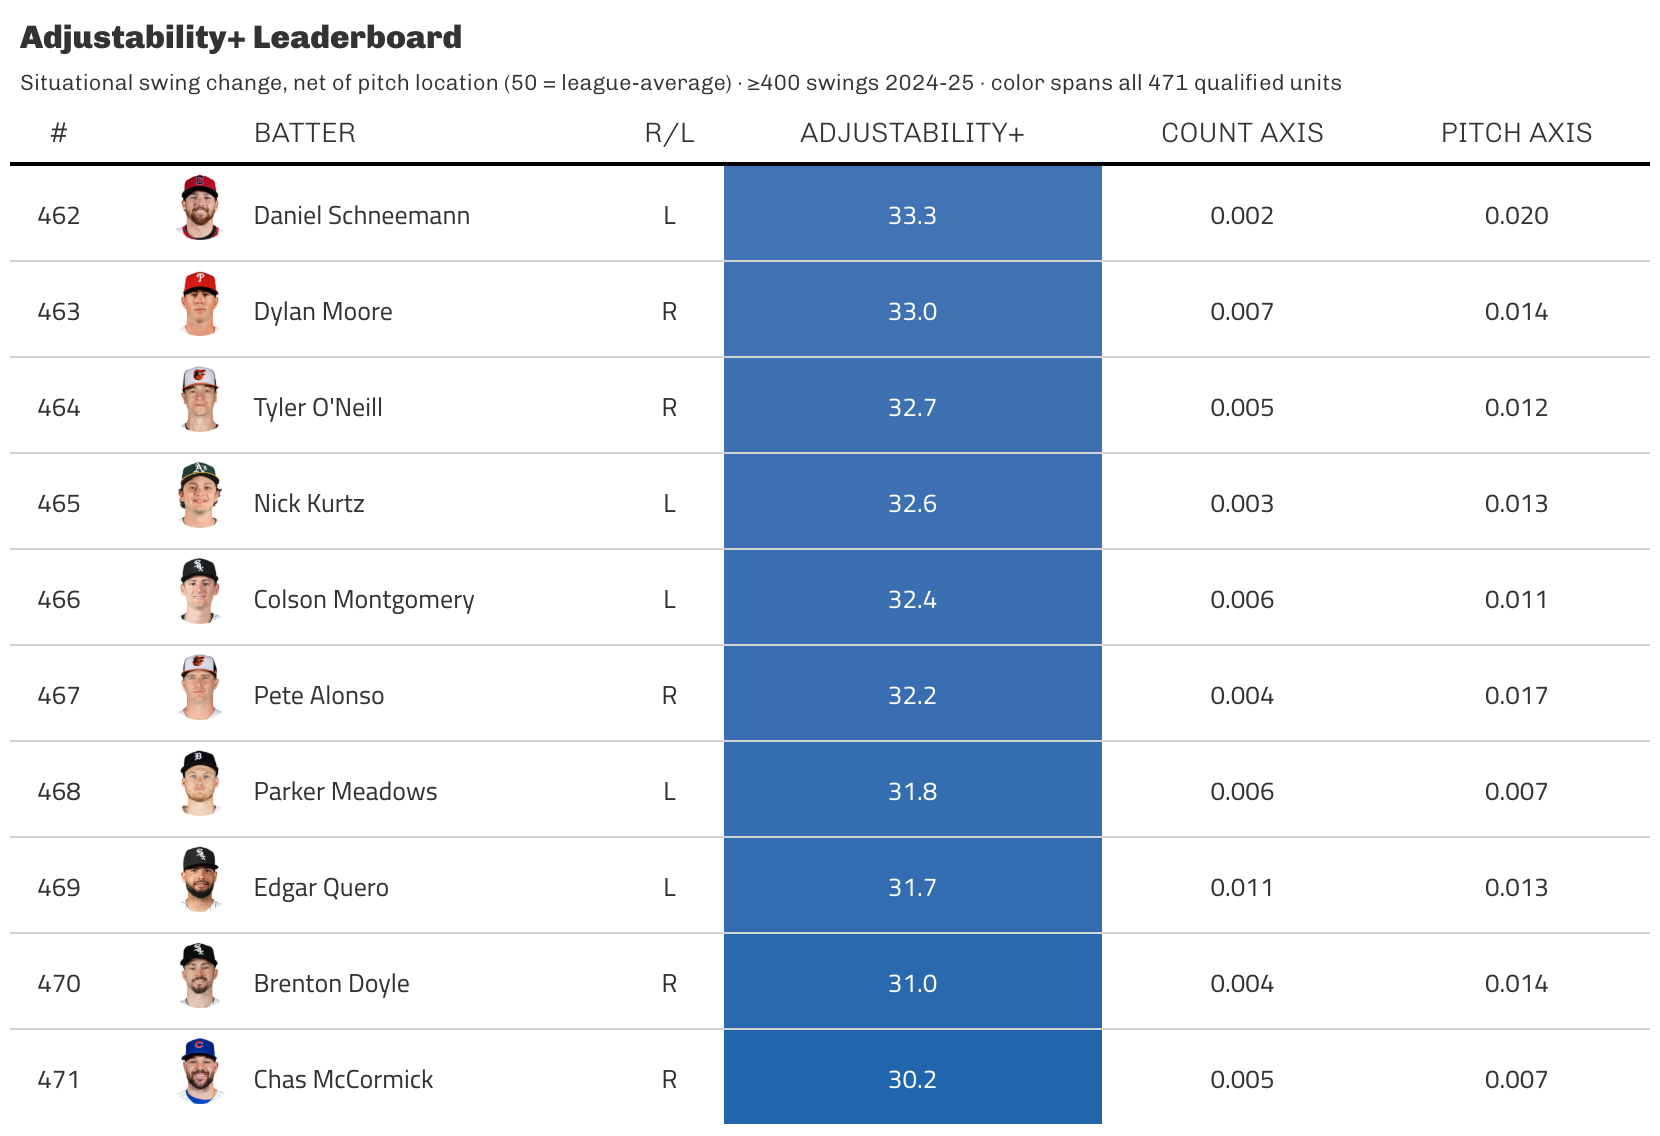

In [13]:
# Adjustability leaderboard (gt + headshots, via R).
# R renders ~8 PNGs via headless Chrome — takes ~5 min on this machine.
# Set REGEN=True to kick off a background rebuild; False (default) shows the last-generated PNGs.
import subprocess, shutil
from IPython.display import Image, display

REGEN = False
RSCRIPT = shutil.which('Rscript') or '/usr/local/bin/Rscript'
if REGEN:
    _r_proc = subprocess.Popen([RSCRIPT, 'src/uncommited/leaderboard_table.R'], cwd=str(ROOT))
    print(f'R leaderboard rebuild started in background (pid={_r_proc.pid}, ~5 min).')

for png in ['adjustability_leaderboard_gt.png', 'adjustability_bottom_gt.png']:
    p = plot_path(png)
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print(f'Not found: {png} — set REGEN=True and re-run.')

# Adjusting Value

In [14]:
cf = pd.read_parquet(DATA / 'adjustability_value.parquet')
judge = cf[cf['label'] == 'Aaron Judge'].iloc[0]
arraez = cf[cf['label'] == 'Luis Arraez'].iloc[0]

print(f'{len(cf)} units loaded')
AXES = ['runs_total', 'runs_count', 'runs_gamestate', 'runs_platoon',
        'runs_interaction', 'runs_total_2k', 'runs_per_swing']
print(cf[AXES].describe().loc[['mean', '50%', 'std', 'min', 'max']].round(4).to_string())


466 units loaded
      runs_total  runs_count  runs_gamestate  runs_platoon  runs_interaction  runs_total_2k  runs_per_swing
mean      0.1397      0.0260         -0.0021        0.1024            0.0133         0.1215          0.0002
50%       0.0334     -0.0409          0.0061        0.0271            0.0185         0.0819          0.0001
std       1.0342      0.9459          0.1844        0.3983            0.2391         0.4599          0.0016
min      -2.7955     -3.2082         -0.9570       -1.1953           -0.6067        -1.4192         -0.0036
max       5.0343      5.1765          0.6994        2.3981            1.0109         2.1887          0.0074


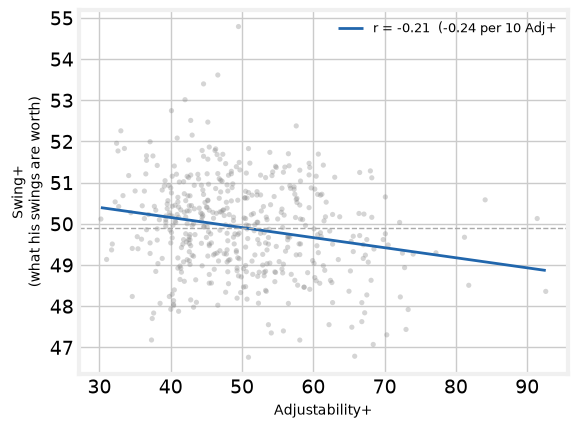

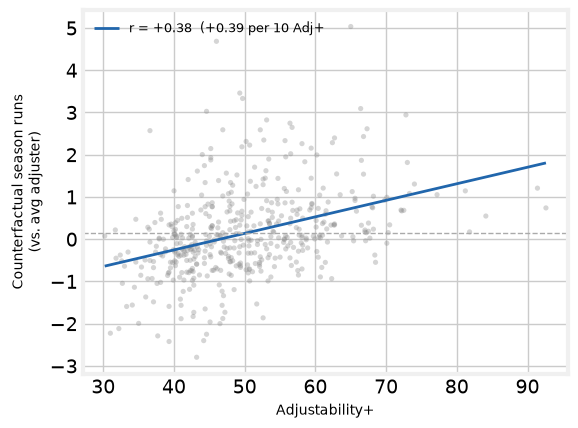

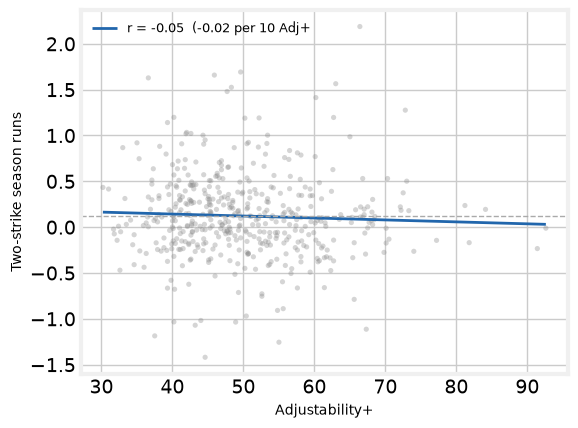

In [15]:
# Adjustability+ against three value metrics — one figure each.
PANELS = [
    ('swing_plus',    'Swing+\n(what his swings are worth)',           'adjustability_does_not_buy_value_swingplus.png'),
    ('runs_total',    'Counterfactual season runs\n(vs. avg adjuster)', 'adjustability_does_not_buy_value_runs.png'),
    ('runs_total_2k', 'Two-strike season runs',                         'adjustability_does_not_buy_value_2k.png'),
]

for col, ylabel, fname in PANELS:
    d = cf[['adjustability_plus', col]].dropna()
    x, y = d['adjustability_plus'].values, d[col].values
    r, _ = stats.pearsonr(x, y)
    b1, b0 = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    with plt.style.context(FT):
        fig, ax = plt.subplots(figsize=(6, 4.5))
        ax.scatter(x, y, s=14, alpha=0.35, color='#888888', edgecolor='none')
        ax.plot(xs, b0 + b1 * xs, color='#2166ac', lw=2,
                label=f'r = {r:+.2f}  ({b1 * 10:+.2f} per 10 Adj+')
        ax.axhline(y.mean(), color='#aaaaaa', lw=1, ls='--')
        ax.set_xlabel('Adjustability+', fontsize=10)
        ax.set_ylabel(ylabel, fontsize=10)
        ax.legend(frameon=False, fontsize=9)
        fig.tight_layout()
        fig.savefig(plot_path(fname), dpi=150, bbox_inches='tight')
        plt.show()


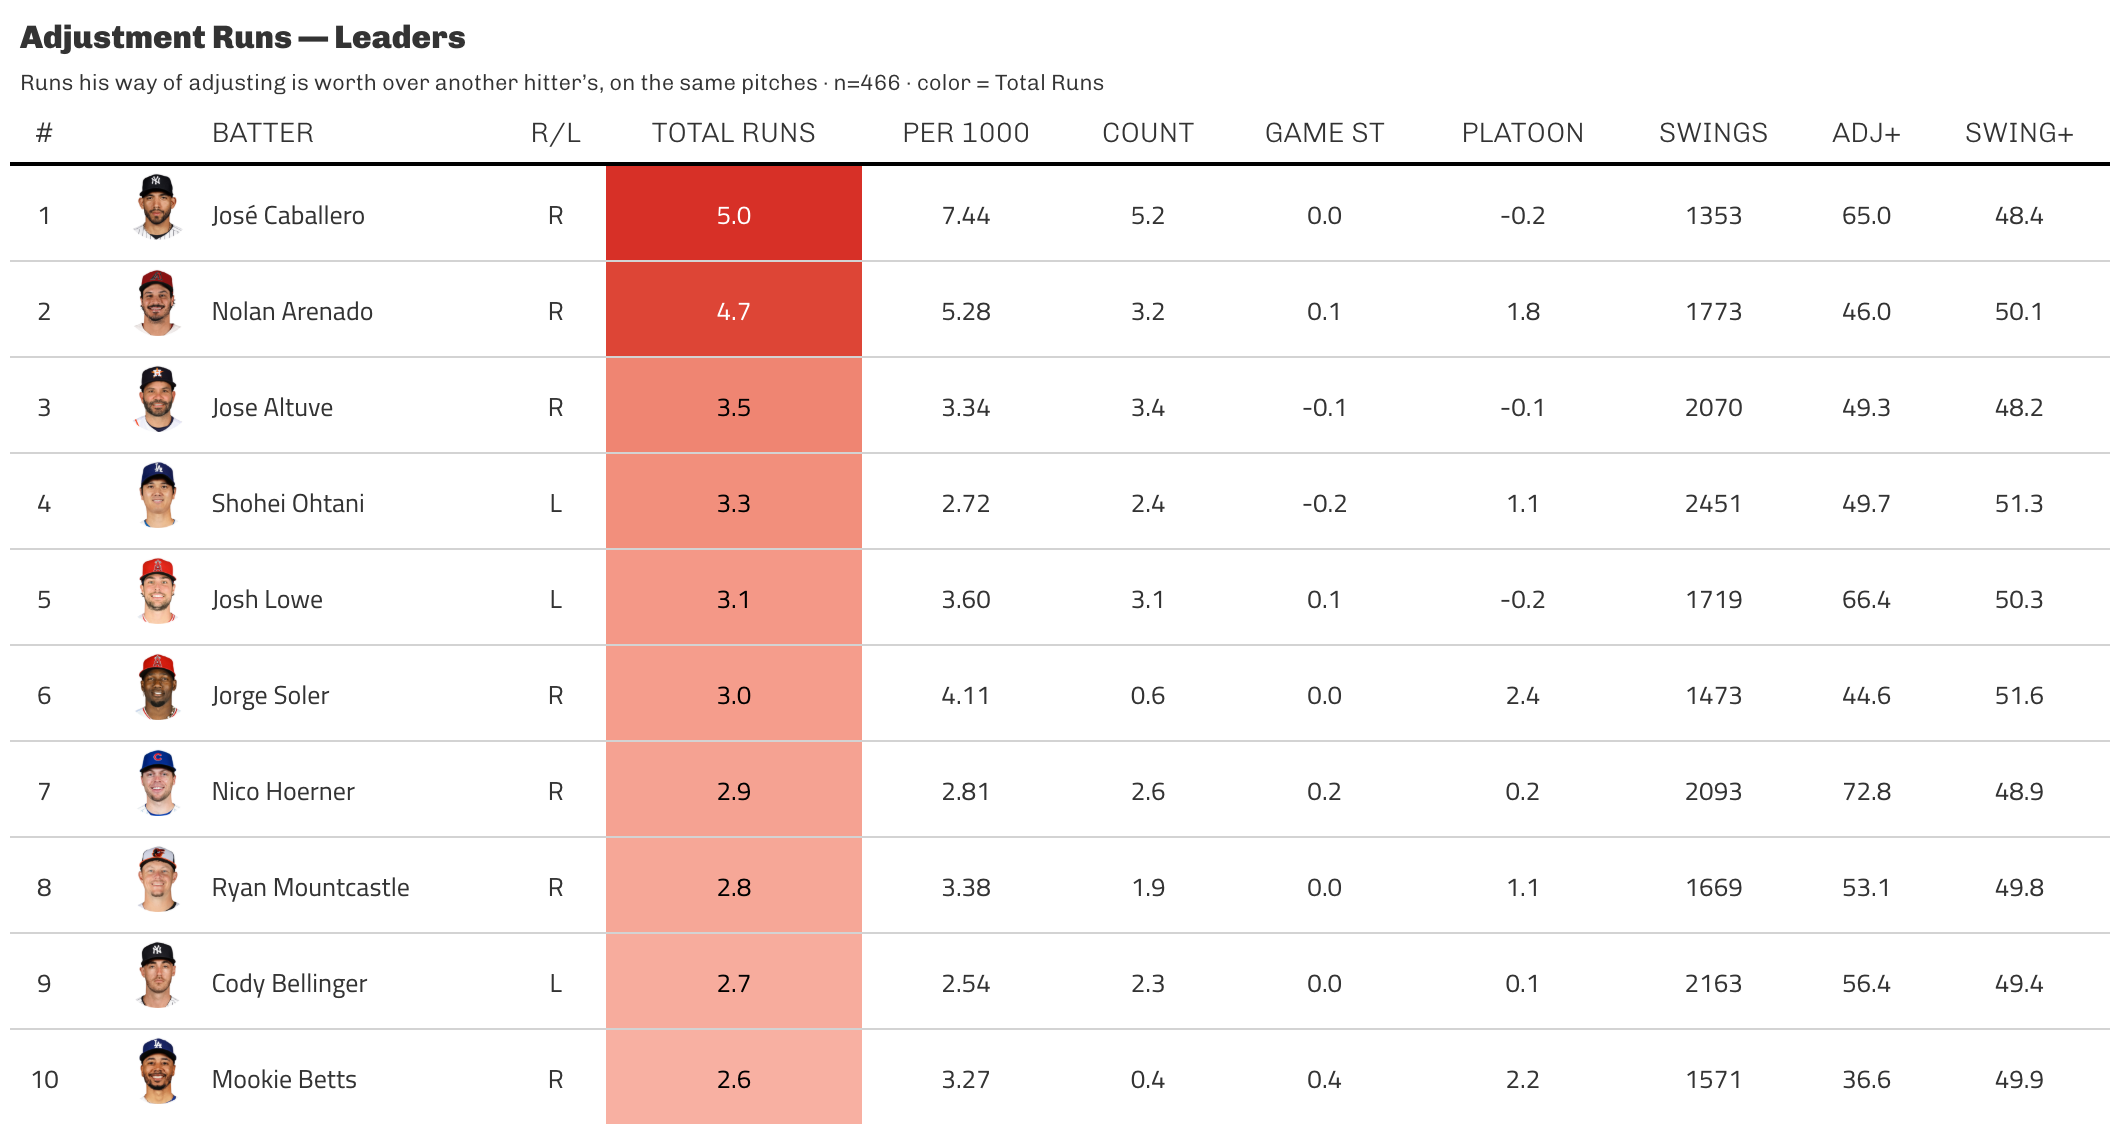

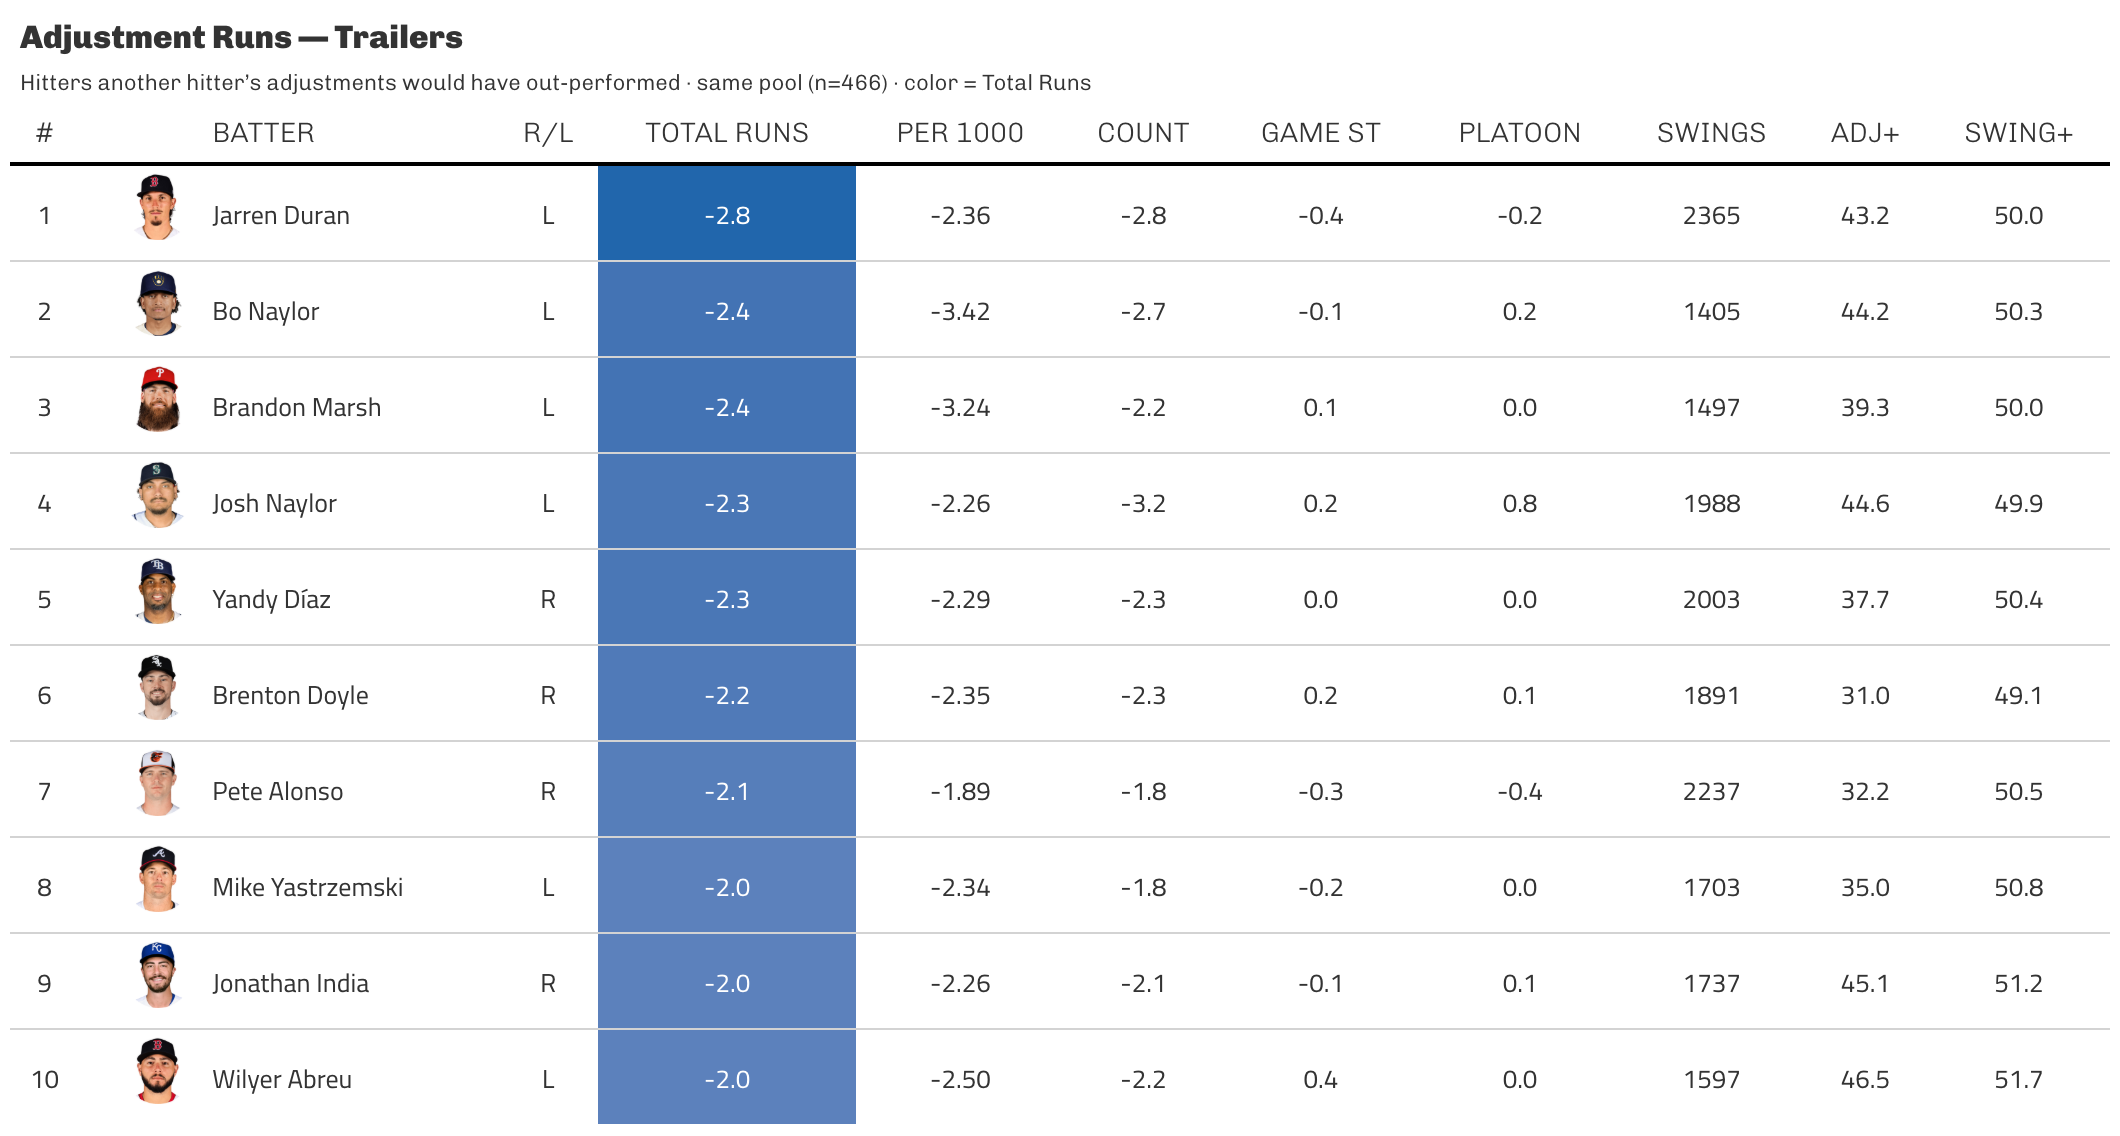

In [16]:
# Leaderboards rendered by src/uncommited/leaderboard_table.R (gt + mlbplotR headshots).
from IPython.display import Image, display

for png in ['adjustability_value_top_gt.png', 'adjustability_value_bottom_gt.png']:
    p = plot_path(png)
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print(f'Not yet generated: {png}')

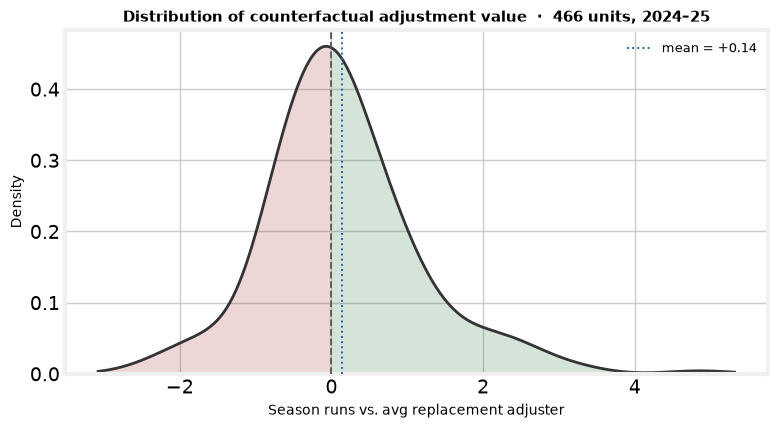

Saved → /Users/theoauyeung/Documents/swing_repertoire/results/plots/adjustability/adjustability_runs_distribution.png


In [17]:
# Distribution of counterfactual season runs across 466 units.
# Annotates Wallner and Morel as examples of the swing-quality/adjustability disconnect:
# both have above-average Swing+ but below-average adjustability value.
from scipy.stats import gaussian_kde
from IPython.display import Image, display

_col = 'runs_total'
vals = cf[_col].values
kde = gaussian_kde(vals, bw_method=0.35)
xs  = np.linspace(vals.min() - 0.3, vals.max() + 0.3, 400)
ys  = kde(xs)

mean_val   = vals.mean()
pct_pos    = (vals > 0).mean() * 100



with plt.style.context(FT):
    fig, ax = plt.subplots(figsize=(8, 4.5))

    # Positive region shading
    mask_pos = xs >= 0
    ax.fill_between(xs[mask_pos], ys[mask_pos], alpha=0.18, color='#1a6b2e', label='_nolabel')
    ax.fill_between(xs[~mask_pos], ys[~mask_pos], alpha=0.18, color='#9b1c1c', label='_nolabel')

    # KDE line
    ax.plot(xs, ys, color='#333333', lw=2)

    # Zero line
    ax.axvline(0, color='#555555', lw=1.3, ls='--', zorder=3)

    # Mean line
    ax.axvline(mean_val, color='#2166ac', lw=1.4, ls=':', zorder=3,
               label=f'mean = {mean_val:+.2f}')

   

    ax.set_xlabel('Season runs vs. avg replacement adjuster', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title('Distribution of counterfactual adjustment value  ·  466 units, 2024–25',
                 fontsize=11, fontweight='bold')
    ax.legend(frameon=False, fontsize=9)
    ax.set_ylim(bottom=0)

    fig.tight_layout()
    _out = plot_path('adjustability_runs_distribution.png')
    fig.savefig(_out, dpi=150, bbox_inches='tight')
    plt.show()

print(f'Saved → {_out}')



# Part III — Which dial to move

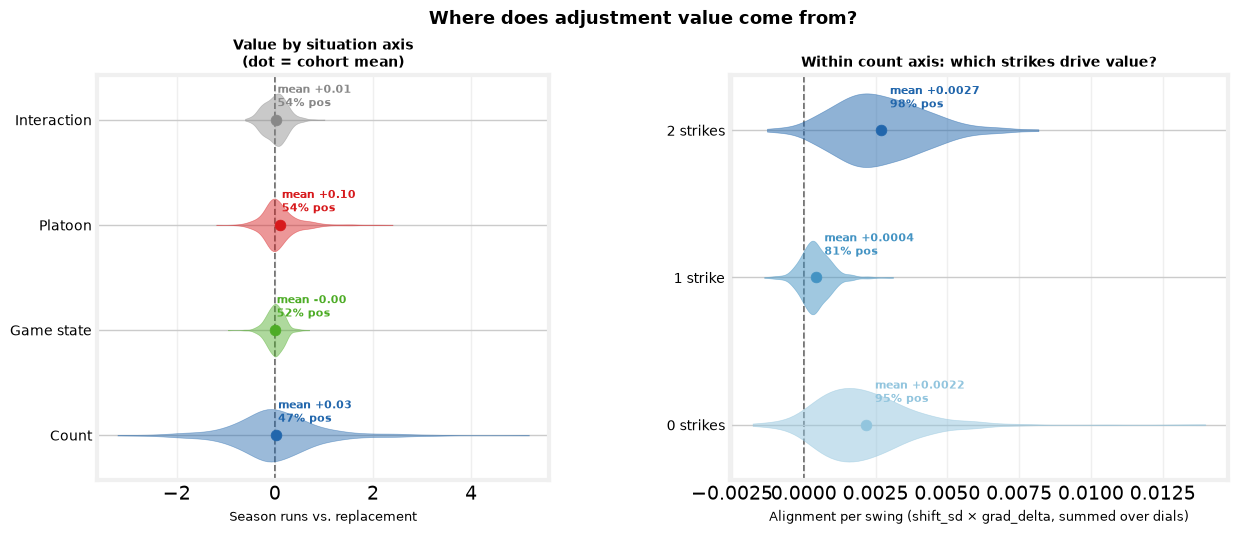

In [18]:
cf = pd.read_parquet(DATA / 'adjustability_value.parquet')
gr = pd.read_parquet(DATA / 'adjustability_gradients.parquet')

AXES = ['runs_count', 'runs_gamestate', 'runs_platoon', 'runs_interaction']
AXIS_LABELS = ['Count', 'Game state', 'Platoon', 'Interaction']
AXIS_COLORS = ['#2166ac', '#4dac26', '#d7191c', '#888888']

# within-count strike alignment: shift_sd * grad_delta per dial, summed per hitter × cell
gr_count = gr[gr.axis == 'count'].copy()
gr_count['align_per_swing'] = gr_count['shift_sd'] * gr_count['grad_delta_runs_per_sd']
KEY = ['batter_id', 'batter_stand']
cell_align = (gr_count.groupby(KEY + ['cell'])['align_per_swing']
              .sum().reset_index().rename(columns={'align_per_swing': 'align'}))

CELL_ORDER = ['0 strikes', '1 strike', '2 strikes']
CELL_COLORS = ['#92c5de', '#4393c3', '#2166ac']

with plt.style.context(FT):
    fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 5),
                                      gridspec_kw={'width_ratios': [1, 1.1], 'wspace': 0.38})
    fig.patch.set_facecolor('white')

    data_by_ax = [cf[c].dropna().values for c in AXES]
    parts = ax_l.violinplot(data_by_ax, positions=range(4), orientation='horizontal',
                            showmedians=False, showextrema=False)
    for pc, col in zip(parts['bodies'], AXIS_COLORS):
        pc.set_facecolor(col); pc.set_alpha(0.45); pc.set_edgecolor(col)
    for i, (col, d, label) in enumerate(zip(AXIS_COLORS, data_by_ax, AXIS_LABELS)):
        mn = np.mean(d)
        pct_pos = 100 * np.mean(d > 0)
        ax_l.scatter(mn, i, color=col, zorder=5, s=60)
        ax_l.text(mn + 0.04, i + 0.22, f'mean {mn:+.2f}\n{pct_pos:.0f}% pos',
                  fontsize=8, va='center', color=col, fontweight='bold')
    ax_l.axvline(0, color='#555', lw=1.2, ls='--', zorder=0)
    ax_l.set_yticks(range(4)); ax_l.set_yticklabels(AXIS_LABELS, fontsize=10)
    ax_l.set_xlabel('Season runs vs. replacement', fontsize=9.5)
    ax_l.set_title('Value by situation axis\n(dot = cohort mean)', fontsize=10, fontweight='bold')
    ax_l.grid(True, axis='x', alpha=0.3)

    for i, (cell, col) in enumerate(zip(CELL_ORDER, CELL_COLORS)):
        vals = cell_align[cell_align.cell == cell]['align'].values
        parts2 = ax_r.violinplot([vals], positions=[i], orientation='horizontal',
                                  showmedians=False, showextrema=False)
        for pc in parts2['bodies']:
            pc.set_facecolor(col); pc.set_alpha(0.5); pc.set_edgecolor(col)
        mn = vals.mean()
        pct = 100 * (vals > 0).mean()
        ax_r.scatter(mn, i, color=col, zorder=5, s=60)
        ax_r.text(mn + 0.0003, i + 0.22, f'mean {mn:+.4f}\n{pct:.0f}% pos',
                  fontsize=8, va='center', color=col, fontweight='bold')
    ax_r.axvline(0, color='#555', lw=1.2, ls='--', zorder=0)
    ax_r.set_yticks(range(3)); ax_r.set_yticklabels(['0 strikes', '1 strike', '2 strikes'], fontsize=10)
    ax_r.set_xlabel('Alignment per swing (shift_sd × grad_delta, summed over dials)', fontsize=9.5)
    ax_r.set_title('Within count axis: which strikes drive value?', fontsize=10, fontweight='bold')
    ax_r.grid(True, axis='x', alpha=0.3)

    fig.suptitle('Where does adjustment value come from?', fontsize=13, fontweight='bold', y=1.01)
    fig.savefig(plot_path('adjustability_situation_breakdown.png'), dpi=150, bbox_inches='tight')
    plt.show()


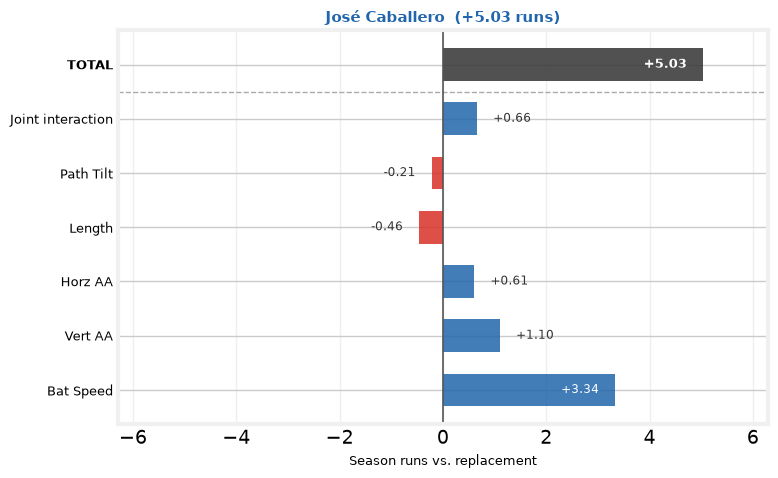

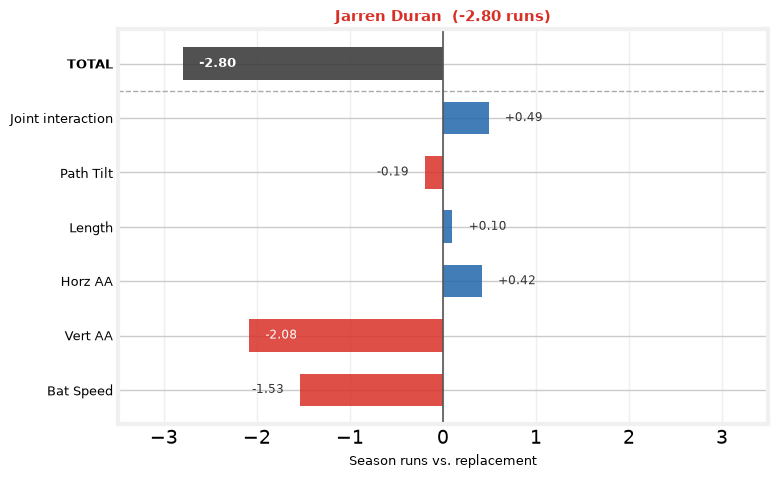

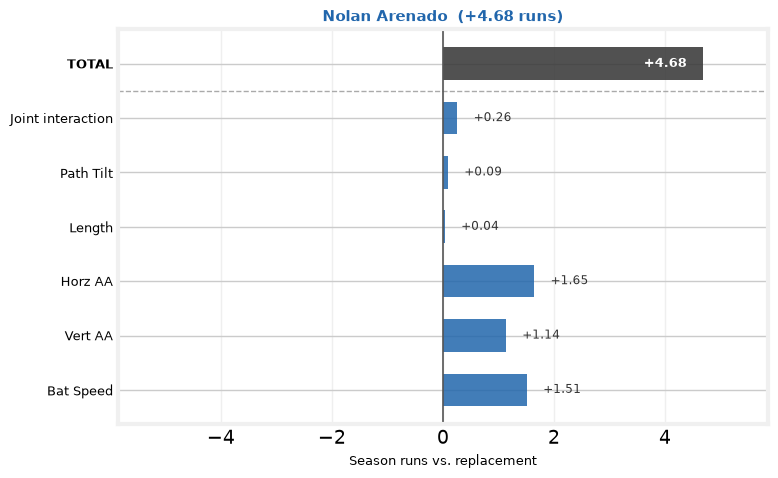

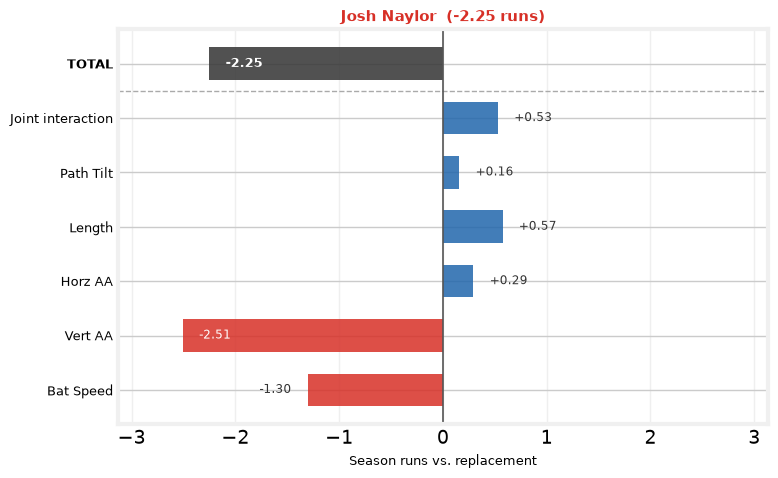

Dial correlations with runs_total:
  bat_speed                      r = +0.775
  vert_attack_angle              r = +0.702
  horz_attack_angle_pull         r = +0.199
  swing_length                   r = -0.401
  swing_path_tilt                r = -0.022
  interaction                    r = +0.012


In [19]:
abl = pd.read_parquet(DATA / 'adjustability_dial_ablation.parquet')

DIAL_ORDER = ['runs_dial_bat_speed', 'runs_dial_vert_attack_angle',
              'runs_dial_horz_attack_angle_pull', 'runs_dial_swing_length',
              'runs_dial_swing_path_tilt', 'runs_dial_interaction']
BAR_LABELS = ['Bat Speed', 'Vert AA', 'Horz AA', 'Length', 'Path Tilt', 'Joint interaction']

FOCAL = [
    ('José Caballero', 'R', '#2166ac'),
    ('Jarren Duran',   'L', '#d73027'),
    ('Nolan Arenado',  'R', '#2166ac'),
    ('Josh Naylor',    'L', '#d73027'),
]

def annotate_bar(ax, v, y, is_total=False):
    fw = 'bold' if is_total else 'normal'
    fs = 9 if is_total else 8.5
    xlim = ax.get_xlim()
    span = xlim[1] - xlim[0]
    # Use a generous threshold so short bars always get outside annotations
    threshold = span * 0.22
    gap = span * 0.025
    if v >= 0:
        if v < threshold:
            ax.text(v + gap, y, f'{v:+.2f}', va='center', ha='left',
                    fontsize=fs, fontweight=fw, color='#333')
        else:
            ax.text(v - gap, y, f'{v:+.2f}', va='center', ha='right',
                    fontsize=fs, fontweight=fw, color='white')
    else:
        if abs(v) < threshold:
            ax.text(v - gap, y, f'{v:+.2f}', va='center', ha='right',
                    fontsize=fs, fontweight=fw, color='#333')
        else:
            ax.text(v + gap, y, f'{v:+.2f}', va='center', ha='left',
                    fontsize=fs, fontweight=fw, color='white')

for name, hand, title_col in FOCAL:
    row = abl[(abl.label == name) & (abl.batter_stand == hand)].iloc[0]
    vals = [row[c] for c in DIAL_ORDER]
    runs_total = row['runs_total']

    all_vals = vals + [runs_total]
    all_labels = BAR_LABELS + ['TOTAL']
    all_colors = ['#2166ac' if v >= 0 else '#d73027' for v in vals] + ['#333333']

    with plt.style.context(FT):
        fig, ax = plt.subplots(figsize=(8, 5))

        y = np.arange(len(all_vals))
        ax.barh(y, all_vals, color=all_colors, height=0.6, alpha=0.85)
        ax.axhline(len(DIAL_ORDER) - 0.5, color='#aaa', lw=1, ls='--')
        ax.axvline(0, color='#555', lw=1.2)

        # Set xlim with padding so outside annotations don't get clipped
        xmax = max(abs(v) for v in all_vals) * 1.25
        ax.set_xlim(-xmax, xmax)

        for i, v in enumerate(all_vals):
            annotate_bar(ax, v, i, is_total=(i == len(DIAL_ORDER)))

        ax.set_yticks(y)
        ax.set_yticklabels(all_labels, fontsize=9)
        for lbl in ax.get_yticklabels():
            if lbl.get_text() == 'TOTAL':
                lbl.set_fontweight('bold')
        ax.set_xlabel('Season runs vs. replacement', fontsize=9)
        ax.set_title(f'{name}  ({runs_total:+.2f} runs)', fontsize=10.5,
                     fontweight='bold', pad=6, color=title_col)
        ax.grid(True, axis='x', alpha=0.3)

        slug = name.split()[-1].lower()
        fig.tight_layout()
        fig.savefig(plot_path(f'adjustability_dial_waterfall_{slug}.png'), dpi=150, bbox_inches='tight')
        plt.show()

# Cohort-level dial correlations with runs_total
print('Dial correlations with runs_total:')
for col in DIAL_ORDER:
    r = abl[col].corr(abl['runs_total'])
    label = col.replace('runs_dial_', '')
    print(f'  {label:<30} r = {r:+.3f}')
